# Ghost Pharmacies

When Bay Area pharmacies closed, did people in cheaper homes lose their nearest pharmacy more often?

This one notebook goes from the raw files in `data/` to every number, chart and map we report.
**Rule:** before submitting, do *Runtime → Restart and run all* (or `Kernel → Restart & Run All`) and make sure it finishes without errors.

Build steps follow the Team Master Guide. Write your name next to the step you own.

## Step 0. Setup
Runs in both Google Colab and a local Jupyter. Edit only the paths in this cell.

In [26]:
import os, sys, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "folium"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    # Shared Drive folder that holds the raw files and receives outputs. Change if yours differs.
    PROJECT_DIR = Path("/content/drive/MyDrive/ghost-pharmacies")
else:
    # Local: the repository root (this notebook lives in notebooks/).
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data"        # raw files, never edited
OUT_DIR = PROJECT_DIR / "outputs"      # everything the notebook creates
FIG_DIR = OUT_DIR / "figures"
MAP_DIR = OUT_DIR / "maps"
for d in (OUT_DIR, FIG_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Raw file names. Rename here if the event files are named differently.
PLACES_CSV = DATA_DIR / "google_maps.csv"
ZILLOW_CSVS = [DATA_DIR / n for n in ["Zillow_part1.csv", "zillow_part2.csv", "zillow_part3.csv"]]   # full Zillow file, in parts: read all and concatenate
CENSUS_CSV = DATA_DIR / "census_tracts.csv"   # optional

# One seed, used everywhere (train/test split, sampling, models).
SEED = 42
random.seed(SEED)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import folium

np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

print("Colab" if IN_COLAB else "Local", "| project dir:", PROJECT_DIR)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| folium", folium.__version__)

Local | project dir: /Users/eriggins/IdeaProjects/ghost-pharmacies
python 3.11.9 | pandas 3.1.1 | numpy 2.4.6 | sklearn 1.9.1 | folium 0.20.0


### Check the raw files
Confirms each file is in place and has the columns the guide relies on. Reads only the header row, so it is fast even on the 500 MB file.

In [27]:
ZILLOW_COLS = ["latitude", "longitude", "county", "bedrooms", "homeStatus", "price",
               "rentZestimate", "getting_around_scores"]
EXPECTED = {
    PLACES_CSV: ["place_id", "name", "category", "lat", "lon", "permanently_closed", "top_reviews"],
    **{p: ZILLOW_COLS for p in ZILLOW_CSVS},
}

for path, cols in EXPECTED.items():
    if not path.exists():
        print(f"MISSING  {path.name}: put it in {DATA_DIR}")
        continue
    header = pd.read_csv(path, nrows=0).columns
    missing = [c for c in cols if c not in header]
    size_mb = path.stat().st_size / 1e6
    status = "OK      " if not missing else "CHECK   "
    print(f"{status} {path.name} ({size_mb:,.0f} MB, {len(header)} columns)"
          + (f" missing: {missing}" if missing else ""))

print("Census (optional):", "found" if CENSUS_CSV.exists() else "not added")

OK       google_maps.csv (506 MB, 41 columns)
OK       Zillow_part1.csv (1,495 MB, 140 columns)
OK       zillow_part2.csv (3,934 MB, 140 columns)
OK       zillow_part3.csv (2,006 MB, 140 columns)
Census (optional): not added


## Step 1. Build the pharmacy table
Owner: ___  
Load Places with `usecols`, keep `category == 'Pharmacy'` (expect about 1,694), add the `chain` column, print closures per chain and compare with the guide.

In [28]:
cols = ['place_id', 'name', 'category', 'lat', 'lon', 'permanently_closed', 'top_reviews'] # get needed columns
p = pd.read_csv(PLACES_CSV, usecols=cols, low_memory=False)
print(len(p))

pharmacies = p[p.category == 'Pharmacy'].copy()
print(len(pharmacies), pharmacies.permanently_closed.sum()) #num pharmacies and num closed

# chains table
CHAINS = [
    ('Walgreens', ['walgreens']),
    ('CVS', ['cvs', 'target']),
    ('Rite Aid', ['rite aid']),
    ('Lucky', ['lucky', 'save mart']),
    ('Safeway', ['safeway']),
    ('Costco', ['costco']),
    ('Walmart', ['walmart']),
    ('Kaiser', ['kaiser']),
    ('Rayleys', ['raley', 'nob hill']), ]

# if chain keywords appear in name, identify as a chain
def chain_of(name):
    n = str(name).lower()
    for chain, keys in CHAINS:
        if any(k in n for k in keys):
            return chain
    return 'Independent'
pharmacies['chain'] = pharmacies['name'].apply(chain_of)
pharmacies.drop(columns='top_reviews').head(10)

147429
1692 524


,place_id,name,category,lat,lon,permanently_closed,chain
44,ChIJJ7Ibd1t8j4ARZ2FG0Xw7Y_s,Walgreens Pharmacy,Pharmacy,37.700780,-122.484303,False,Walgreens
128,ChIJMfTsjB9nhYAR6n_6ZjC7bYQ,Diablo Professional Pharmacy,Pharmacy,37.984643,-122.036154,True,Independent
337,ChIJq6o2ZguQhYAREvFyBFAIWt4,Pharmaca Integrative Pharmacy,Pharmacy,37.904155,-122.542290,True,Independent
509,ChIJeWbogxgyjoART71-F7zRwY0,Safeway Pharmacy,Pharmacy,37.267140,-121.833175,False,Safeway
571,ChIJDzdZCOZvhYARO8EgyzmimLQ,Rite Aid Pharmacy,Pharmacy,38.054624,-122.155252,True,Rite Aid
691,ChIJy-NyFsWPj4ARGN85LlnT8VQ,Medical Arts Pharmacy,Pharmacy,37.714412,-122.142271,False,Independent
858,ChIJk_jA5oUgjoAR8jz3mH9C540,Walgreens Pharmacy,Pharmacy,37.129916,-121.638607,False,Walgreens
861,ChIJC5cXpzeQj4ARZCRQ_sy53tA,Walgreens Pharmacy,Pharmacy,37.685806,-122.138247,False,Walgreens
971,ChIJs2suXUCij4ARIAN1d1HeY5o,Rph,Pharmacy,37.500029,-122.241142,False,Independent
1061,ChIJDe8uw6Z-hYARGsgDDkGZbP0,CVS Pharmacy,Pharmacy,37.881282,-122.269022,False,CVS


## Step 2. Decide which closures are real
Owner: ___  
Distance from each closed pharmacy to the nearest open one (BallTree, haversine). Real closure = not Rite Aid or Lucky and no open pharmacy within 50 m (expect about 358). Save `outputs/pharmacies_clean.csv`.

In [29]:
def distance(lat1, lon1, lat2, lon2): #haversine formula -> distance in meters between two lat/lon points on earth
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2]) # convert to radians
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2 #distance between two points on sphere
    return 2 * 6371000 * np.arcsin(np.sqrt(a)) # turn a into meters

pharmacies = pharmacies.dropna(subset=['lat', 'lon']).copy() #pharmacies with no coordinates
open_pharm = pharmacies[pharmacies.permanently_closed == False] #tables of pharmacies still open

def nearest_open(row):
    return distance(row.lat, row.lon, open_pharm.lat.values, open_pharm.lon.values).min()

closed = pharmacies.permanently_closed == True 
pharmacies.loc[closed, 'm_to_open'] = pharmacies[closed].apply(nearest_open, axis=1) # for closed pharmacies store meters to the nearest open pharmacy

pharmacies['chain_shutdown'] = pharmacies.chain.isin(['Rite Aid', 'Lucky']) #flag rite aid and lucky as chain shutdown
pharmacies['real_closure'] = closed & ~pharmacies.chain_shutdown & (pharmacies.m_to_open > 50) # real closure -> closed, not a chain shutdown, no open pharmacy within 50m

print(closed.sum(), pharmacies.real_closure.sum())
pharmacies.to_csv(OUT_DIR / 'pharmacies_clean.csv', index=False)
    

524 358


## Step 3. Hand-check
Owner: ___  
30 real closures + 10 open pharmacies sampled with `SEED`, checked on Google Maps. Load the results table here and report the error rate.

In [30]:
sample = pd.concat([
    pharmacies[pharmacies.real_closure].sample(30, random_state=SEED),
    pharmacies[pharmacies.permanently_closed == False].sample(10, random_state=SEED),
]) #random sample
sample[['name', 'chain', 'lat', 'lon', 'real_closure']].to_csv(OUT_DIR / 'handcheck.csv', index=False) 
#handchecked_done is in outputs

In [31]:
# scoring cell

done = pd.read_csv(OUT_DIR / 'handcheck_done.csv')
wrong = (done['correct'].str.lower() == 'no').sum() 
print(f"{wrong} wrong out of {len(done)} = {wrong / len(done):.0%} error rate")

2 wrong out of 40 = 5% error rate


## Step 4. Build the rent level
Owner: ___  
Load Zillow (use `chunksize` if needed), drop missing coordinates, compute rent and relative rent by bedrooms, keep \$500 to \$20,000 and 0 to 5 bedrooms, split into thirds within county.

In [32]:
# TODO

## Step 5. Access-loss analysis
Owner: ___  
Nearest-pharmacy distance before and after for every home, the two-sided table, with and without chain shutdowns, broken down by county.

In [33]:
# TODO

## Step 6. Split the data and train the first model
Owner: ___  
80/20 split stratified on the label with `random_state=SEED`. Save test IDs to `outputs/test_ids.csv`. **Do not look at test scores until Step 8.** Baseline: logistic regression on chain only. Model: gradient boosting. Compare with cross-validation on the training set.

In [58]:
not_shutdown = pharmacies.chain_shutdown == False;
real_or_open = (pharmacies.real_closure == True) | (pharmacies.permanently_closed == False)
d = pharmacies[not_shutdown & real_or_open].copy()
d['y'] = d.real_closure.astype('int') #answer col
print(len(d), d.y.sum())

1523 358


In [59]:
# num of place within
def count_within(row, others, meters):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    return (d_all <= meters).sum()

# median score of 10 nearest
def median_near(row, others, column):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    closest10 = np.argsort(d_all)[:10] #positions of the 10 closest homes
    return np.median(others[column].values[closest10]) #middle value of those 10
    
# nearest pharmacy
def next_nearest(row):
    d_all = distance(row.lat, row.lon, pharmacies.lat.values, pharmacies.lon.values)
    return np.sort(d_all)[1]
    
# distance of each pharmacy kept to every pharmacy in the full table

d['within_500m'] = d.apply(count_within, axis=1, others=pharmacies, meters=500) -1
d['within_1km'] = d.apply(count_within, axis=1, others=pharmacies, meters=1000) -1
d['within_3km'] = d.apply(count_within, axis=1, others=pharmacies, meters=3000) -1
d['meters_to_next'] = d.apply(next_nearest, axis=1)


In [60]:
places = pd.read_csv(PLACES_CSV, usecols=['category', 'lat', 'lon']).dropna() #places tbl
grocery = places[places.category.str.contains('grocery', case=False)] #grocery tbl
clinic = places[places.category.str.contains('clinic', case=False)] #bus stops tbl
bus = places[places.category.str.contains('bus', case=False)] #clinics tbl
homes = pd.read_csv(OUT_DIR / 'homes_clean.csv').rename(columns={'latitude': 'lat', 'longitude': 'lon'}) #homes tbl
rent_homes = homes.dropna(subset=['lat', 'lon', 'rel_rent']) #homes with a rent level
walk_homes = homes.dropna(subset=['lat', 'lon', 'walk_score']) #homes with a walk score
print(len(rent_homes), len(walk_homes)) #how many of each

d['grocery_1km'] = d.apply(count_within, axis=1, others=grocery, meters=1000) #new column for grocery stores within 1km
d['clinic_1km'] = d.apply(count_within, axis=1, others=clinic, meters=1000) #new column for clinics within 1km
d['bus_1km'] = d.apply(count_within, axis=1, others=bus, meters=1000) #new column for bus stops within 1km
d['rent_near'] = d.apply(median_near, axis=1, others=rent_homes, column='rel_rent') #new column for rent level of 10 closest homes
d['walk_near'] = d.apply(median_near, axis=1, others=walk_homes, column='walk_score') #new column for walk score of 10 closest homes

chains = pd.get_dummies(d.chain, prefix='is', dtype=int) #makes new columns for each chain, ex. is_CVS gets 1 or 0 
d = d.join(chains)
chain_cols = list(chains.columns) #save chain cols
features = ['within_500m', 'within_1km', 'within_3km', 'meters_to_next', 'grocery_1km', 'clinic_1km', 'bus_1km', 'rent_near', 'walk_near'] + chain_cols #req features for model to look at


134835 114032


In [62]:
from sklearn.model_selection import train_test_split, cross_val_score

train, test = train_test_split(d, test_size=0.2, stratify=d.y, random_state=SEED) #shuffle and deal into 2 tabls, 20% in test 80% in train
test[['place_id']].to_csv(OUT_DIR / 'test_ids.csv', index=False) #save and exclude test ids
print(len(train), len(test))



1218 305


In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

baseline = LogisticRegression(max_iter=1000) #baseline model
model = GradientBoostingClassifier(random_state=SEED) #our model

baseline_score = cross_val_score(baseline, train[chain_cols], train.y, cv=5, scoring='roc_auc').mean() # prediction knowing only the chain
model_score = cross_val_score(model, train[features], train.y, cv=5, scoring='roc_auc').mean() # prediction with neighborhood data
print('baseline', round(baseline_score, 3))
print('model', round(model_score, 3))


d.to_csv(OUT_DIR / 'features.csv', index=False)

baseline 0.62
model 0.722


## Step 7. Improve the model, carefully
Owner: ___  
Two or three changes, judged by cross-validation on training only. No `rating`, `reviews_count`, `open_hours` or `is_claimed` (they leak). Freeze the model at the end of this step.

In [12]:
# TODO

## Step 8. Final evaluation and fairness
Owner: ___  
Score model and baseline on the test set once. AUC, plus precision and recall for the top 20%. Subgroups: low, middle, high rent; chain vs independent. Five failure examples.

In [66]:
from sklearn.metrics import roc_auc_score

model.fit(train[features], train.y) #model studies the training set
baseline.fit(train[chain_cols], train.y) #baseline studies it too

ev = train.copy() #the table we grade on
ev['risk'] = model.predict_proba(ev[features])[:, 1] #closure risk from 0 to 1
ev['base_risk'] = baseline.predict_proba(ev[chain_cols])[:, 1]

print('model AUC', round(roc_auc_score(ev.y, ev.risk), 3))
print('baseline AUC', round(roc_auc_score(ev.y, ev.base_risk), 3))

model AUC 0.927
baseline AUC 0.626


In [67]:
top = ev[ev.risk >= ev.risk.quantile(0.8)] #the 20% the model rates riskiest
print('precision', round(top.y.mean(), 3)) #share of those that really closed
print('recall', round(top.y.sum() / ev.y.sum(), 3)) #share of all closures we caught

precision 0.824
recall 0.703


In [68]:
ev['rent_group'] = pd.qcut(ev.rent_near, 3, labels=['low', 'middle', 'high']) #split into rent thirds

for group in ['low', 'middle', 'high']:
    g = ev[ev.rent_group == group]
    print(group, 'rent', round(roc_auc_score(g.y, g.risk), 3))

indep = ev[ev.chain == 'Independent']
chain = ev[ev.chain != 'Independent']
print('independent', round(roc_auc_score(indep.y, indep.risk), 3))
print('chain', round(roc_auc_score(chain.y, chain.risk), 3))

low rent 0.917
middle rent 0.906
high rent 0.959
independent 0.896
chain 0.948


                                name        lat         lon      risk
69878   Walgreens Specialty Pharmacy  37.818948 -122.262517  0.628289
119491            Walgreens Pharmacy  37.789015 -122.408830  0.601378
54193             Walgreens Pharmacy  37.858148 -122.267228  0.524445
                     name        lat         lon      risk
13310  Walgreens Pharmacy  37.724934 -121.944201  0.090792
34787    Safeway Pharmacy  37.935966 -121.699160  0.092896


<Axes: >

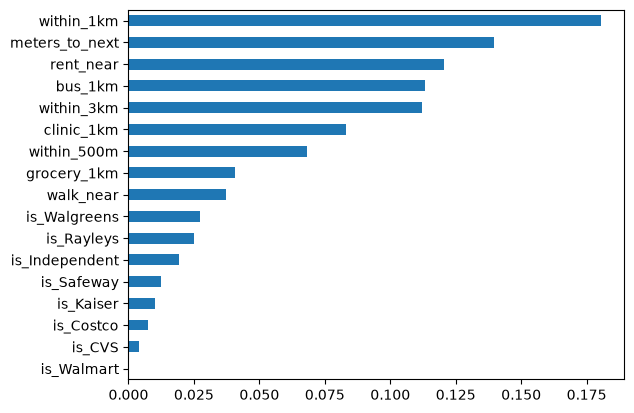

In [69]:
print(ev[ev.y == 0].nlargest(3, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated risky, still open
print(ev[ev.y == 1].nsmallest(2, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated safe, but closed

pd.Series(model.feature_importances_, index=features).sort_values().plot.barh() #which features mattered most

## Step 9. Map and charts
Owner: ___  
Save charts to `FIG_DIR` and the folium map to `MAP_DIR`. Two-sided bars, 800 m before/after, model vs baseline, "last pharmacy standing" list.

In [ ]:
# TODO

## Step 10. Package
Owner: ___  
Restart and run all from the raw files. Update the README.

In [ ]:
# TODO